# 📊 Análisis Visual de Datos de Entrenamiento

En este cuaderno cargaremos nuestro dataset ya limpio (`datos_limpios.csv`) para crear gráficos exploratorios que nos permitan ver la evolución de las calorías, los pulsos y las duraciones de los entrenamientos a lo largo del tiempo.



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo visual de los gráficos para que se vean modernos
sns.set_theme(style="whitegrid")

# 1. Cargamos nuestro archivo CSV limpio
# (Asegurate de subir 'datos_limpios_nuevos_valores.csv' a la solapa de archivos de este nuevo Colab)
df = pd.read_csv('datos_limpios.csv')

# 2. Convertimos la columna Fecha de nuevo a datetime por las dudas
df['Fecha'] = pd.to_datetime(df['Fecha'])

# 3. Miramos las primeras filas para confirmar que cargó perfecto
print("--- PRIMERAS FILAS DEL DATASET LIMPIO ---")
display(df.head())

--- PRIMERAS FILAS DEL DATASET LIMPIO ---


,Duración,Fecha,Pulso,Maxpulso,Calorías
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
3,45,2020-12-04,109,175,282.4
4,45,2020-12-05,117,148,406.0


## 2. Evolución Temporal de Calorías Quemadas

Vamos a graficar cómo variaron las calorías quemadas en cada fecha de entrenamiento para identificar picos de actividad.

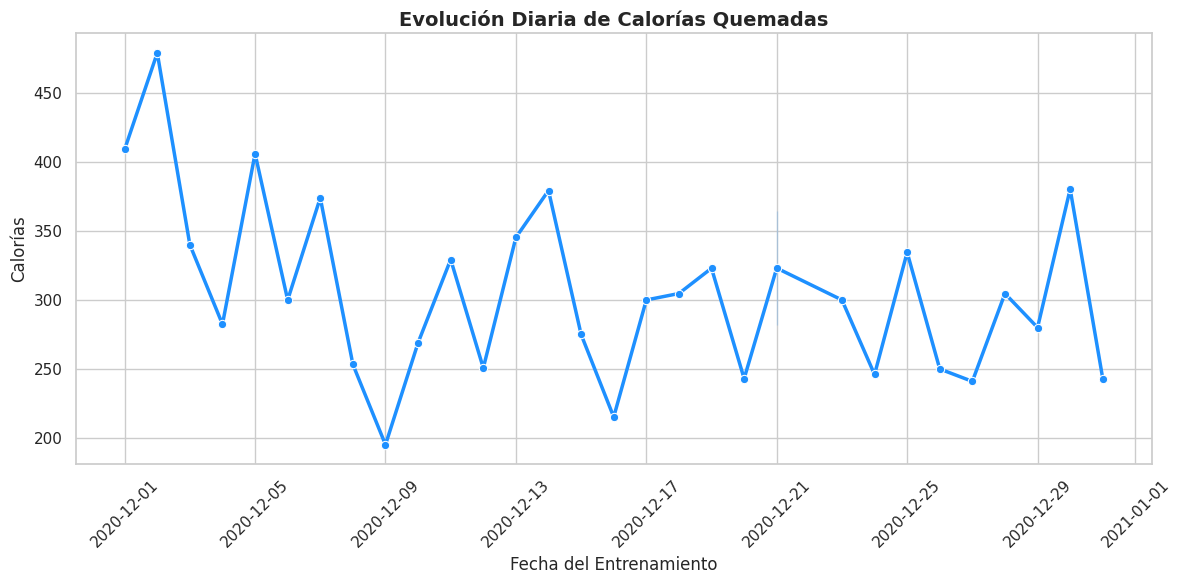

In [2]:
# Configuramos el tamaño de la figura para que se vea grande y prolija
plt.figure(figsize=(12, 6))

# Creamos el gráfico de línea con Seaborn
# x = Fecha, y = Calorías
sns.lineplot(
    data=df,
    x='Fecha',
    y='Calorías',
    marker='o',          # Le pone un puntito en cada registro para que se note cada día
    color='dodgerblue',  # ponemos un azul
    linewidth=2.5
)

# Personalizamos el título y los ejes para que tenga nivel profesional
plt.title('Evolución Diaria de Calorías Quemadas', fontsize=14, fontweight='bold')
plt.xlabel('Fecha del Entrenamiento', fontsize=12)
plt.ylabel('Calorías', fontsize=12)

# Rotamos un poco las fechas del eje X para que no se encimen los textos
plt.xticks(rotation=45)

# Mostramos el gráfico limpio
plt.tight_layout()
plt.show()

## 3. Relación entre Duración del Entrenamiento y Calorías Quemadas

Mediante un gráfico de dispersión con línea de tendencia, analizaremos si existe una correlación directa entre los minutos invertidos en la rutina y la cantidad de calorías quemadas.

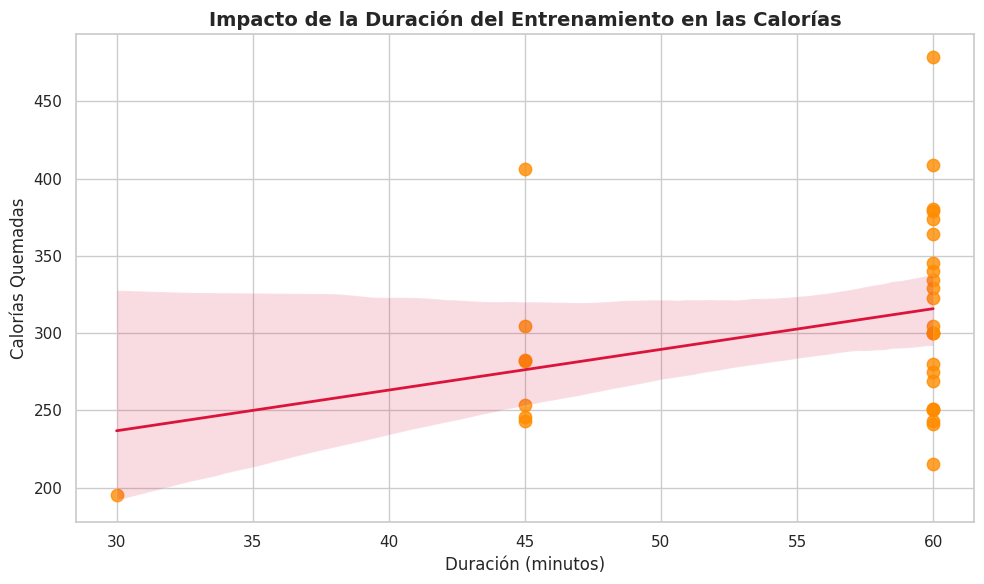

In [3]:
# Configuramos el tamaño del gráfico
plt.figure(figsize=(10, 6))

# Usamos regplot de Seaborn para graficar los puntos y agregar una línea de tendencia automática
sns.regplot(
    data=df,
    x='Duración',
    y='Calorías',
    color='darkorange',                 # Color de los puntos
    scatter_kws={'s': 80, 'alpha': 0.8},# Tamaño y transparencia de los puntos
    line_kws={'color': 'crimson', 'linewidth': 2} # Línea de tendencia en rojo para que resalte
)

# Personalizamos con títulos profesionales
plt.title('Impacto de la Duración del Entrenamiento en las Calorías', fontsize=14, fontweight='bold')
plt.xlabel('Duración (minutos)', fontsize=12)
plt.ylabel('Calorías Quemadas', fontsize=12)

# Mostramos el gráfico limpio
plt.tight_layout()
plt.show()

## 4. Matriz de Correlación y Mapa de Calor

Para finalizar el análisis exploratorio (EDA), utilizaremos un mapa de calor para visualizar el coeficiente de correlación de Pearson entre las distintas variables numéricas. Esto nos ayuda a identificar rápidamente qué métricas están más relacionadas entre sí.

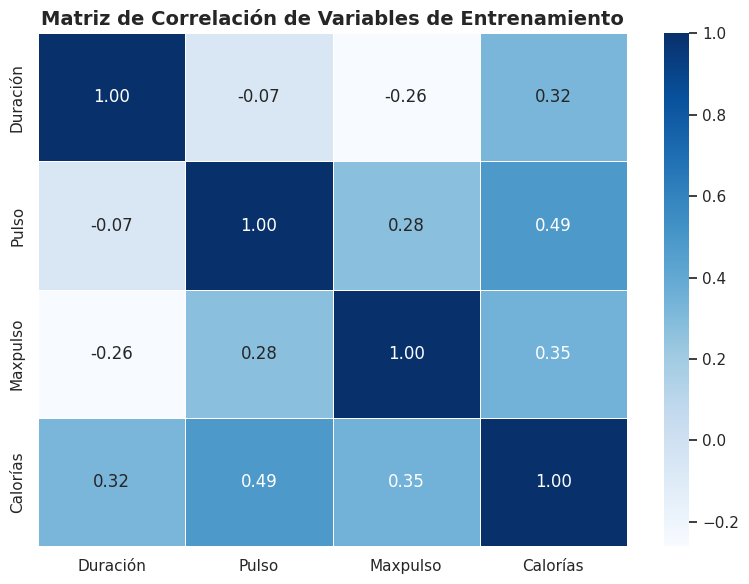

In [4]:
# 1. Calculamos la matriz de correlación de nuestras variables numéricas
# (Ignoramos la columna de fechas porque es de tipo datetime)
matriz_corr = df[['Duración', 'Pulso', 'Maxpulso', 'Calorías']].corr()

# 2. Configuramos el tamaño del gráfico
plt.figure(figsize=(8, 6))

# 3. Creamos el mapa de calor con Seaborn
sns.heatmap(
    matriz_corr,
    annot=True,        # Muestra los números exactos dentro de cada recuadro
    cmap='Blues',      # Paleta de colores en tonos azules (¡ideal para tu color favorito!)
    fmt='.2f',         # Muestra los números con dos decimales
    linewidths=0.5,    # Líneas divisorias prolijas entre los casilleros
    cbar=True          # Muestra la barra de referencia de color al costado
)

# Título profesional
plt.title('Matriz de Correlación de Variables de Entrenamiento', fontsize=14, fontweight='bold')

# Mostramos el gráfico limpio
plt.tight_layout()
plt.show()

## 📌 Conclusiones Finales y Recomendaciones Estratégicas

Tras realizar la limpieza del dataset y el Análisis Exploratorio de Datos (EDA), se destacan las siguientes conclusiones para la toma de decisiones:

1. **Intensidad sobre Duración (Heatmap):**
   * La correlación entre **Pulso** y **Calorías** ($0.49$) es superior a la de **Duración** y **Calorías** ($0.32$).
   * *Decisión:* Priorizar el trabajo de frecuencia cardíaca (intensidad) para optimizar el tiempo de quienes buscan maximizar la quema calórica.

2. **Eficiencia en Sesiones (Regplot):**
   * Las sesiones de 45 minutos logran en varios casos la misma quema calórica que las de 60 minutos.
   * *Decisión:* Promover rutinas de 45 minutos de alta intensidad como el estándar más eficiente de entrenamiento.

3. **Monitoreo de Consistencia (Lineplot):**
   * Se identifican fluctuaciones importantes entre días consecutivos.
   * *Decisión:* Implementar un calendario de periodización de cargas para evitar picos de fatiga y caídas drásticas en el rendimiento.